In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import sys
import ast
import os
import matplotlib.patheffects as path_effects
sys.path.append('../')
from utils.Evaluation.calculate_metrics_tzo import calculate_scores
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as path_effects
sns.set_style(style='whitegrid')  # Better background
from collections import defaultdict, Counter
from typing import List, Tuple, Dict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import sem
from matplotlib.cm import get_cmap
import colorsys
import numpy as np
import matplotlib.pyplot as plt
import ast
import statistics

In [2]:
def extract_params(model_name):
    import re
    match = re.search(r'([\d.]+)[bB]', model_name)
    if match:
        return float(match.group(1))
    return 1000  # Default if no match

def count_tries(row):
    path = row['path']
    cypher_corrector_freq = path.count('cypher_corrector')
    # if 'schema_retriever' in path:
    #     # KG valid with full schema
    #     if 'output_generator' in path:
    #         count = cypher_corrector_freq - 5
    #     # Unvailable Output
    #     else:
    #         count = None
    # # KG Valid with filtered schema
    # else:
    count = cypher_corrector_freq
    return count

def remove_duplicates(row):
    unique_elements =row[:len(row) // 2]
    return unique_elements

def extract_error_types_as_lists(nested_list):
    return [[s.split(':')[0].strip() for s in sublist] for sublist in nested_list]

def extract_error_types(nested_list):
    return [s.split(':')[0] for sublist in nested_list for s in sublist]

def calculate_dicts_with_usage(source_directory,extended=True):
    dict_with_models={}
    for name in os.listdir(source_directory):
        folder_path = os.path.join(source_directory, name)
        if os.path.isdir(folder_path):
            # “name” is an immediate folder
            print(f"Entering folder: {folder_path}")
            # do your work here, e.g. list files inside:
            for file in os.listdir(folder_path):
                file_path = os.path.join(folder_path, file)
                if file.endswith('_usage.xlsx'):
                    print(f"Entering file: {file}")
                    df_all = pd.read_excel(file_path)
                    
                    if 'Sustain' in file_path:
                        df = df_all
                    else:
                        df = df_all[df_all['Original_KG_Valid']==True].reset_index(drop=True)
                    
                    if extended:
                        list_columns = ['path','cypher_errors_history', 'cypher_errors']
                        for col in list_columns:
                            df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
                        
                        # Extract error types from cypher_errors_history
                        df['cypher_errors_history'] = df['cypher_errors_history'].apply(remove_duplicates)
                        df['flattened_cypher_errors_history'] = df['cypher_errors_history'].apply(extract_error_types)
                        df['cypher_errors_codes_history'] = df['cypher_errors_history'].apply(extract_error_types_as_lists)
                        # df['cypher_errors_codes_with_categories'] = df['cypher_errors_codes_history'].apply(map_errors_codes_to_categories)
                        # df['cypher_errors_with_categories'] = df['cypher_errors_history'].apply(map_errors_to_categories)
                        
                    # For rows that isKG_Valid_correct is not present, we calculate it
                    # if 'is_KG_Valid' not in df.columns:
                    #     df['is_KG_Valid'] = (
                    #                                     (df['Schema Valid'] == 1) &
                    #                                     ((df['Properties Valid'] == 1) | df['Properties Valid'].isna()) &
                    #                                     (df['Syntax Valid'] == True)
                    #                                 )
                    #     df['is_KG_Valid'] = df['is_KG_Valid'].astype(bool)   
                    model_name = file.split('.')[0]
                    model_name = model_name.replace('openrouter_', '')
                    model_name = model_name.replace('_local', '')
                    dict_with_models[model_name] = df        

    return dict_with_models

In [3]:
# SustainDataset
models_mapping = {
    'gpt_4o':'gpt4o', 
    'llama3_2_3b':'Llama-3.2-3B-Instruct',
    'qwen2_5_7b':'Qwen2.5-7B-Instruct',
    'qwen2_5_Coder_32b':'Qwen2.5-Coder-32B-Instruct',
    'qwen2_5_72b':'Qwen2.5-72B-Instruct',
}

dataset = 'SustainDataset'

In [4]:
#Get all the dataframes with the results thate nd in _usage.xlsx
extended_dfs_dict = calculate_dicts_with_usage("./extended_workflow/Outputs_Evaluation/"+dataset,extended=True)
extended_dfs_dict = dict(sorted(extended_dfs_dict.items(), key=lambda item: extract_params(item[0])))
extended_dfs_dict.keys()
basic_dfs_dict = calculate_dicts_with_usage("./basic_workflow/Outputs_Evaluation/"+dataset,extended=False)
basic_dfs_dict = dict(sorted(basic_dfs_dict.items(), key=lambda item: extract_params(item[0])))
basic_dfs_dict.keys()
langgraph_dfs_dict = calculate_dicts_with_usage("./langgraph_workflow/Outputs_Evaluation/"+dataset,extended=False)
langgraph_dfs_dict = dict(sorted(langgraph_dfs_dict.items(), key=lambda item: extract_params(item[0])))
# langgraph_dfs_dict.keys()

Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\gpt_4o
Entering file: gpt_4o_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\llama3_2_3b
Entering file: llama3_2_3b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\qwen2_5_72b
Entering file: qwen2_5_72b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\qwen2_5_7b
Entering file: qwen2_5_7b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\qwen2_5_Coder_32b
Entering file: qwen2_5_Coder_32b_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset\gpt_4o
Entering file: gpt_4o_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset\llama3_2_3b
Entering file: llama3_2_3b_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset\llama3_2_3b_local
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset\qwen2_5_72b
Ent

## For each iter

In [6]:
stats = []

for phase, model_dict in [
    ('Basic Workflow', basic_dfs_dict),
    ('Extended Workflow', extended_dfs_dict),
    ('Langgraph Workflow', langgraph_dfs_dict)
]:
    for model_name, df in model_dict.items():
        if phase == 'Extended Workflow':
            df['Iteration'] = df.apply(count_tries, axis=1)

            for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
                if col in df.columns:
                    if isinstance(df[col].iloc[0], str):
                        df[col] = df[col].apply(ast.literal_eval)
                    # compute sum ignoring -1
                    df[col + '_sum'] = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))

            # Now compute metrics **per iteration**
            for iteration, iter_df in df.groupby('Iteration'):
                metrics = {
                    'Median Time (s) & iqr':  f"{round(iter_df['eval_time_s'].median(), 2)} & {(iter_df['eval_time_s'].quantile(0.75) - iter_df['eval_time_s'].quantile(0.25)):.2f}" if not iter_df['eval_time_s'].empty else "N/A",
                    'Median Prompt Tokens & iqr': f"{iter_df['prompt_tokens_sum'].median():.2f} & {(iter_df['prompt_tokens_sum'].quantile(0.75) - iter_df['prompt_tokens_sum'].quantile(0.25)):.2f}" if 'prompt_tokens_sum' in iter_df.columns else "N/A"
                }

                for metric, value in metrics.items():
                    stats.append({
                        'Model': models_mapping[model_name.rstrip('_usage')],
                        'Phase': phase,
                        'Iteration': iteration,
                        'Metric': metric,
                        'Count': value
                    })

# Create DataFrame
melted_df = pd.DataFrame(stats)
melted_df['Params'] = melted_df['Model'].apply(extract_params)
melted_df = melted_df.sort_values(by=['Params'])


df_wide = melted_df.pivot_table(
    index='Model',
    columns=['Metric','Iteration'],
    values='Count',
    aggfunc='first'
)
df_wide = df_wide.reset_index()
df_wide['Params'] = df_wide.Model.apply(extract_params)
df_wide = df_wide.sort_values(by=['Params'])


df_pivot = melted_df.pivot_table(
    index=['Metric', 'Iteration'],
    columns='Model',
    values='Count',
    aggfunc='first'  # or 'mean' if duplicates exist
).reset_index()

df_pivot

Model,Metric,Iteration,Llama-3.2-3B-Instruct,Qwen2.5-72B-Instruct,Qwen2.5-7B-Instruct,Qwen2.5-Coder-32B-Instruct,gpt4o
0,Median Prompt Tokens & iqr,0,740.00 & 1496.00,1354.00 & 2792.00,718.00 & 1229.00,1354.00 & 1967.00,1342.50 & 2876.00
1,Median Prompt Tokens & iqr,1,4796.00 & 3864.00,2956.00 & 3634.00,4039.50 & 5888.75,9009.50 & 1984.25,3877.00 & 2560.50
2,Median Prompt Tokens & iqr,2,7430.50 & 5772.50,13485.00 & 0.00,10252.50 & 5750.50,15226.50 & 6219.50,13947.00 & 0.00
3,Median Prompt Tokens & iqr,3,13886.50 & 7289.50,21530.00 & 0.00,11494.50 & 6816.50,4835.50 & 1299.50,NaN
4,Median Prompt Tokens & iqr,5,6482.00 & 0.00,NaN,3693.00 & 0.00,NaN,NaN
5,Median Prompt Tokens & iqr,6,43146.00 & 0.00,NaN,NaN,NaN,NaN
6,Median Prompt Tokens & iqr,7,29955.00 & 0.00,NaN,NaN,NaN,NaN
7,Median Prompt Tokens & iqr,8,NaN,NaN,60459.00 & 0.00,NaN,NaN
8,Median Prompt Tokens & iqr,9,NaN,46999.00 & 0.00,NaN,NaN,NaN
9,Median Prompt Tokens & iqr,10,53120.00 & 16284.50,53947.00 & 0.00,53807.00 & 19476.00,52932.00 & 0.00,NaN


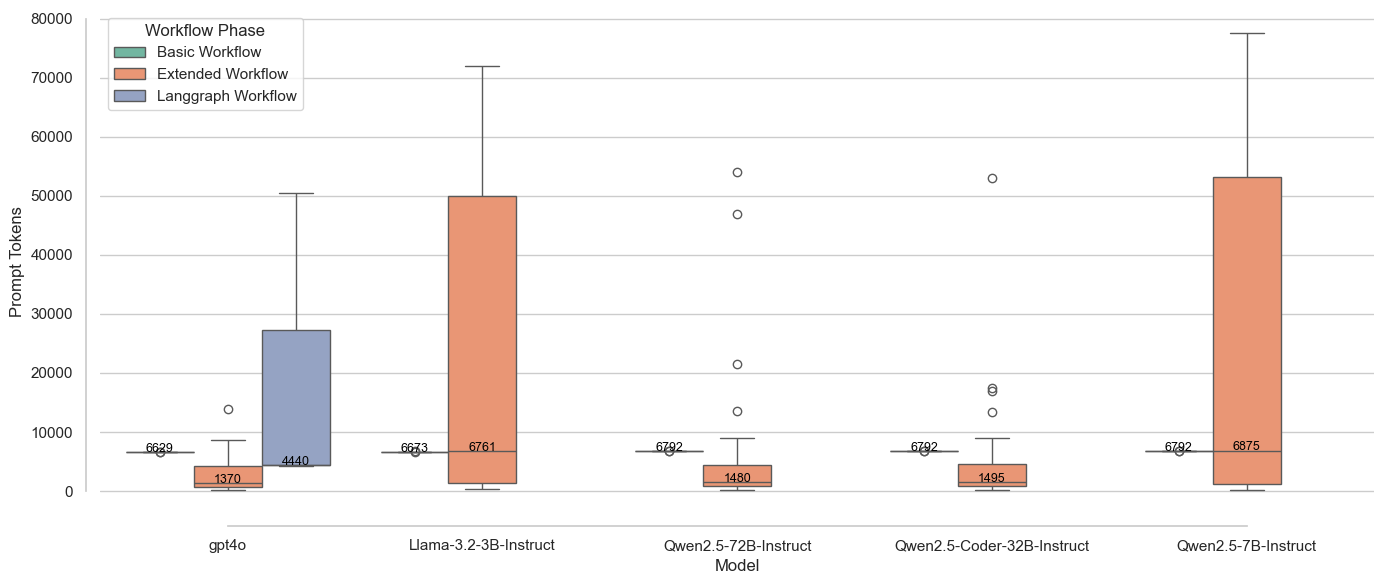

In [24]:
workflows = [
    ('Basic Workflow', basic_dfs_dict),
    ('Extended Workflow', extended_dfs_dict),
    ('Langgraph Workflow', langgraph_dfs_dict)
]

# Prepare plot data
plot_data = []
for phase, wdict in workflows:
    for model, df in wdict.items():
        for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
            if col in df.columns:
                if isinstance(df[col].iloc[0], str):
                    df[col] = df[col].apply(ast.literal_eval)
                df[col+'_sum'] = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
        if 'prompt_tokens_sum' in df.columns:
            temp_df = df[['prompt_tokens_sum']].copy()
            temp_df['Model'] = models_mapping.get(model.rstrip('_usage'), model)
            temp_df['Phase'] = phase
            plot_data.append(temp_df)

if not plot_data:
    raise ValueError("No data found to plot!")

plot_df = pd.concat(plot_data, ignore_index=True)
plot_df['Params'] = plot_df['Model'].apply(extract_params)
plot_df = plot_df.sort_values(["Params"]).reset_index(drop=True)
median_order = plot_df.groupby('Model')['prompt_tokens_sum'].median().sort_values().index

# Plot
plt.figure(figsize=(14,6))
ax = sns.boxplot(
    x='Model', y='prompt_tokens_sum', hue='Phase', data=plot_df,
    order=median_order, palette='Set2', showfliers=True
)

# Annotate medians robustly
medians = plot_df.groupby(['Model', 'Phase'])['prompt_tokens_sum'].median().reset_index()
phases = list(plot_df['Phase'].unique())
for _, row in medians.iterrows():
    if row['Model'] not in median_order:
        continue
    x = list(median_order).index(row['Model'])
    width = 0.8 / len(phases)
    x_coord = x - 0.4 + width/2 + phases.index(row['Phase'])*width
    ax.text(x_coord, row['prompt_tokens_sum']+2, f"{int(row['prompt_tokens_sum'])}", 
            ha='center', fontsize=9, color='black')

plt.ylabel('Prompt Tokens')
plt.xlabel('Model')
plt.xticks(rotation=45, ha='right')
sns.despine(offset=10, trim=True)
plt.legend(title='Workflow Phase')
plt.tight_layout()
plt.show()

C:\Users\ioann\AppData\Local\Temp\ipykernel_8060\2479813626.py:48: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  medians = tokens_df.groupby(['Model','Phase'])['prompt_tokens_sum'].median().reset_index()


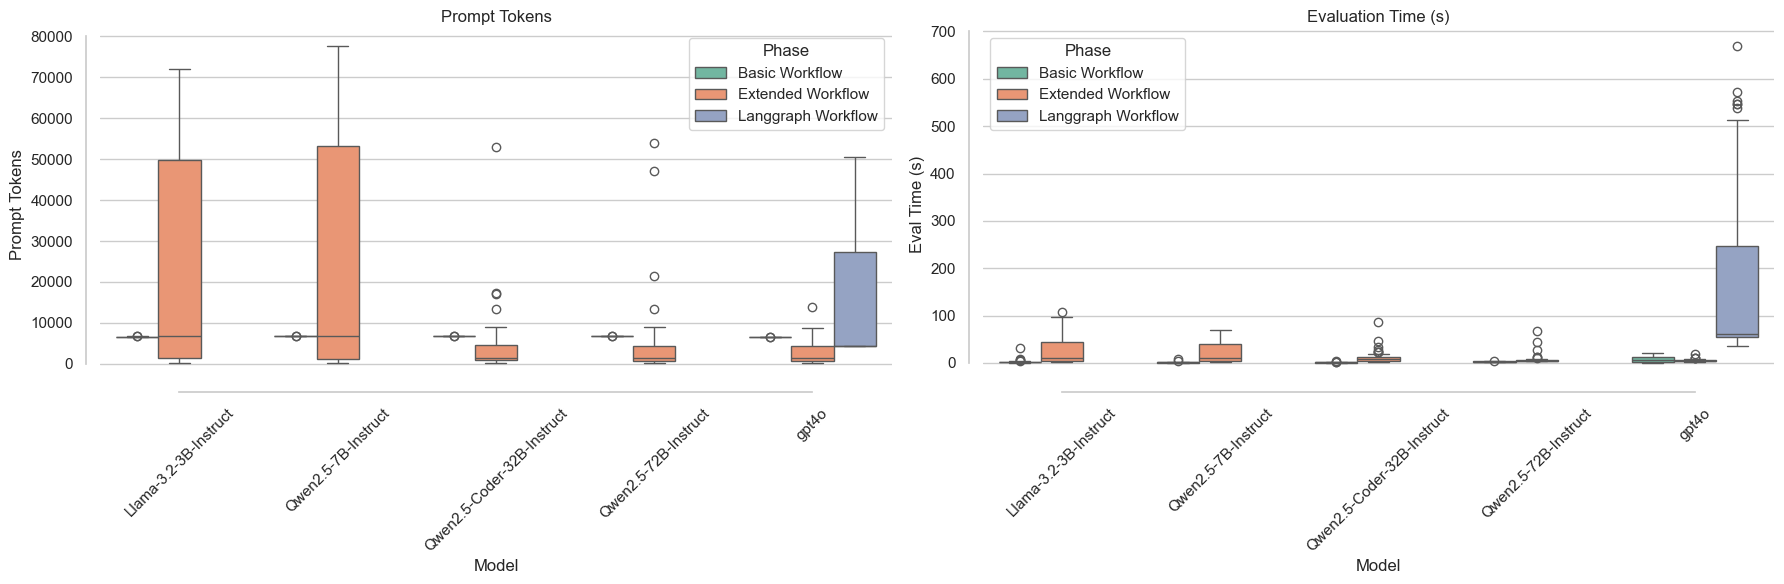

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import ast

# ---- Prepare prompt_tokens_sum data ----
plot_data = []
for phase, wdict in workflows:
    for model, df in wdict.items():
        for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
            if col in df.columns and isinstance(df[col].iloc[0], str):
                df[col] = df[col].apply(ast.literal_eval)
                df[col+'_sum'] = df[col].apply(lambda x: sum(int(v) for v in x if int(v)!=-1))
        if 'prompt_tokens_sum' in df.columns:
            temp_df = df[['prompt_tokens_sum']].copy()
            temp_df['Model'] = models_mapping.get(model.rstrip('_usage'), model)
            temp_df['Phase'] = phase
            plot_data.append(temp_df)
tokens_df = pd.concat(plot_data, ignore_index=True)
tokens_df['Params'] = tokens_df['Model'].apply(extract_params)
median_order = tokens_df.drop_duplicates('Model').sort_values('Params')['Model']
tokens_df['Model'] = pd.Categorical(tokens_df['Model'], categories=median_order, ordered=True)

# ---- Prepare eval_time_s data ----
eval_data = []
for phase, wdict in workflows:
    for model, df in wdict.items():
        if 'eval_time_s' in df.columns:
            temp_df = df[['eval_time_s']].copy()
            temp_df['Model'] = models_mapping.get(model.rstrip('_usage'), model)
            temp_df['Phase'] = phase
            eval_data.append(temp_df)
eval_df = pd.concat(eval_data, ignore_index=True)
eval_df['Model'] = pd.Categorical(eval_df['Model'], categories=median_order, ordered=True)

# ---- Plot both subplots ----
sns.set(style="whitegrid")
fig, axes = plt.subplots(1,2, figsize=(18,6))

# Prompt tokens
sns.boxplot(x='Model', y='prompt_tokens_sum', hue='Phase', data=tokens_df,
            palette='Set2', showfliers=True, ax=axes[0])
axes[0].set_title('Prompt Tokens'); axes[0].set_ylabel('Prompt Tokens'); axes[0].set_xlabel('Model')
axes[0].tick_params(axis='x', rotation=45)
sns.despine(offset=10, trim=True, ax=axes[0])
# Annotate medians
phases = list(tokens_df['Phase'].unique())
medians = tokens_df.groupby(['Model','Phase'])['prompt_tokens_sum'].median().reset_index()
for _, row in medians.iterrows():
    x = list(tokens_df['Model'].cat.categories).index(row['Model'])
    width = 0.8 / len(phases)
    x_coord = x - 0.4 + width/2 + phases.index(row['Phase'])*width
    # axes[0].text(x_coord, row['prompt_tokens_sum']+2, f"{int(row['prompt_tokens_sum'])}", ha='center', fontsize=9)

# Eval time
sns.boxplot(x='Model', y='eval_time_s', hue='Phase', data=eval_df,
            palette='Set2', showfliers=True, ax=axes[1])
axes[1].set_title('Evaluation Time (s)'); axes[1].set_ylabel('Eval Time (s)'); axes[1].set_xlabel('Model')
axes[1].tick_params(axis='x', rotation=45)
sns.despine(offset=10, trim=True, ax=axes[1])

plt.tight_layout()
plt.show()


In [32]:
stats = []
for phase, model_dict in [('Basic Workflow', basic_dfs_dict), ('Extended Workflow', extended_dfs_dict),('Langgraph Workflow', langgraph_dfs_dict)]:
    for model_name, df in model_dict.items():
        for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
            if col in df.columns:
                if isinstance(df[col].iloc[0], str):
                    df[col] = df[col].apply(ast.literal_eval)
                # ignore -1
                token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
                df[col + '_sum'] = token_sums
        metrics = {
            'Median Time (s) & iqr':  f"{round(df['eval_time_s'].median(), 2)} & {(df['eval_time_s'].quantile(0.75) - df['eval_time_s'].quantile(0.25)):.2f}",
            'Median Prompt Tokens & iqr':  f"{df['prompt_tokens_sum'].median():.2f} & {(df['prompt_tokens_sum'].quantile(0.75) - df['prompt_tokens_sum'].quantile(0.25)):.2f}",
            # '(Min,Max Time (s))': ', '.join(map(str, (
            #     round(df['eval_time_s'].min(), 2),
            #     round(df['eval_time_s'].max(), 2)
            # ))),
            # '(Min,Max Total Tokens)': ', '.join(map(str, (
            #     round(df['total_tokens_sum'].min(), 2),
            #     round(df['total_tokens_sum'].max(), 2)
            # ))),
            # '(Filtered,Full,Unavailable)': ', '.join(map(str, (
            #     round((len(df[df['Group'] == 'KG Valid Queries (Filtered Schema)'])/len(df)*100),2),
            #     round((len(df[df['Group'] == 'KG Valid Queries (Full Schema)'])/len(df)*100),2),
            #     round((len(df[df['Group'] == 'Unavailable Output'])/len(df)*100),2)
            # ))) if phase == 'Extended Workflow' else None,        
                  }
        for metric, count in metrics.items():
            stats.append({
                'Model': models_mapping[model_name.rstrip('_usage')],
                'Phase': phase,
                'Metric': metric,
                'Count': count
            })

# Create DataFrame
melted_df = pd.DataFrame(stats)
melted_df['Params'] = melted_df['Model'].apply(extract_params)
melted_df = melted_df.sort_values(by=['Params'])

df_wide = melted_df.pivot_table(
    index='Model',
    columns=['Metric', 'Phase'],
    values='Count',
    aggfunc='first'
)
df_wide = df_wide.reset_index()
df_wide['Params'] = df_wide.Model.apply(extract_params)
df_wide = df_wide.sort_values(by=['Params'])
df_wide

Metric                       Model Median Prompt Tokens & iqr  \
Phase                                          Basic Workflow   
0            Llama-3.2-3B-Instruct            6673.00 & 11.00   
2              Qwen2.5-7B-Instruct            6792.50 & 11.00   
3       Qwen2.5-Coder-32B-Instruct            6792.50 & 11.00   
1             Qwen2.5-72B-Instruct            6792.50 & 11.00   
4                            gpt4o            6629.00 & 11.00   

Metric                                         Median Time (s) & iqr  \
Phase    Extended Workflow  Langgraph Workflow        Basic Workflow   
0       6761.50 & 48463.25                 NaN            1.9 & 1.38   
2       6875.00 & 52005.00                 NaN           0.92 & 0.60   
3        1495.50 & 3776.25                 NaN           1.24 & 0.70   
1        1480.50 & 3666.25                 NaN           2.65 & 0.90   
4        1370.50 & 3507.75  4440.50 & 22879.50          5.72 & 12.00   

Metric                                       Params  
Phase  Extended Workflow Langgraph Workflow          
0          10.59 & 40.42                NaN     3.0  
2          11.39 & 35.84                NaN     7.0  
3             7.5 & 6.96                NaN    32.0  
1            4.97 & 1.77                NaN    72.0  
4            4.28 & 2.33     61.13 & 192.75  1000.0